# DSCO 2026 — Prediksi Mahasiswa Berisiko (`at_risk`)

**Tugas:** klasifikasi biner — memprediksi apakah seorang mahasiswa berisiko (`at_risk = 1`) dari data demografi, asesmen awal, dan aktivitas belajar daring 4 minggu pertama.
**Metrik:** F1 score.

**Isi notebook**

1. Setup
2. Exploratory Data Analysis (EDA)
3. Preprocessing
4. Pemilihan model
5. Evaluasi model
6. Prediksi data test & file submission
7. Insight preskriptif

**Kepatuhan aturan:** hanya memakai `train.csv` dan `test.csv` dari panitia, tanpa data eksternal, tanpa AutoML, tanpa model pre-trained, tanpa mengubah label. Semua seed dikunci agar hasil dapat direproduksi dengan *Run All*.

## 1. Setup

In [1]:
import os, time, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import f1_score, roc_auc_score, precision_score, recall_score, confusion_matrix, classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline

import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostClassifier

SEED = 42
N_FOLDS = 5
N_JOBS = 4
np.random.seed(SEED)

SUBMISSION_NO = 3  # nomor urut submission; nama file: submission_<nomor>.csv

# CSV dibaca dari folder yang sama dengan notebook (sesuai ketentuan panitia).
# Fallback ke ../data/raw/ hanya untuk struktur folder kerja tim.
DATA_DIR = "" if os.path.exists("train.csv") else "../data/raw/"
OUT_DIR = "../submissions/" if os.path.isdir("../submissions") else ""

C0, C1, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#898781"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": "#52514e", "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left", "font.size": 9,
})

In [2]:
train = pd.read_csv(DATA_DIR + "train.csv")
test = pd.read_csv(DATA_DIR + "test.csv")
sample_sub = pd.read_csv(DATA_DIR + "sample_submission.csv")

TARGET = "at_risk"
print("train:", train.shape, "| test:", test.shape, "| sample_submission:", sample_sub.shape)
train.head()

train: (26086, 64) | test: (6502, 63) | sample_submission: (6502, 2)


,id,code_module,code_presentation,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,...,week4_interactions,interaction_trend,early_interactions,late_interactions,late_to_early_interactions_ratio,avg_interactions_per_active_day,active_weeks,avg_interactions_per_active_week,activity_span_days,at_risk
0,1,M01,P12,M,Region1,HE Qualification,90-100%,55<=,0,240,...,0,-46.9,203,100,0.492611,43.285714,3,101.00,18,0
1,2,M01,P12,F,Region6,HE Qualification,20-30%,35-55,0,60,...,125,-17.9,241,162,0.672199,33.583333,4,100.75,28,0
2,3,M01,P12,F,region2,A Level,30-40%,35-55,0,60,...,0,-39.3,179,0,0.000000,29.833333,2,89.50,8,1
3,4,M01,P12,F,Region 10,A Level,50-60%,35-55,0,60,...,41,1.1,176,149,0.846591,19.117647,4,81.25,27,0
4,5,M01,P12,F,Region9,Lower Than A Level,50-60%,0-35,0,60,...,58,-8.8,177,95,0.536723,17.000000,4,68.00,25,0


## 2. Exploratory Data Analysis

### 2.1 Struktur data dan target

Tipe kolom: {dtype('int64'): 40, dtype('float64'): 16, dtype('O'): 8}
NaN train: 0 | NaN test: 0
Baris duplikat penuh (tanpa id): 4
Rentang id train: 1 - 26091 | test: 26092 - 32593

Distribusi target:
         jumlah  proporsi
at_risk                  
0         12333    0.4728
1         13753    0.5272


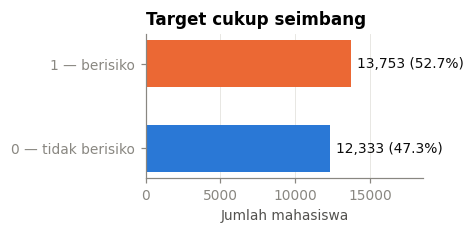

In [3]:
print("Tipe kolom:", train.dtypes.value_counts().to_dict())
print("NaN train:", int(train.isna().sum().sum()), "| NaN test:", int(test.isna().sum().sum()))
print("Baris duplikat penuh (tanpa id):", int(train.drop(columns="id").duplicated().sum()))
print("Rentang id train:", train.id.min(), "-", train.id.max(), "| test:", test.id.min(), "-", test.id.max())

vc = train[TARGET].value_counts().sort_index()
print("\nDistribusi target:")
print(pd.DataFrame({"jumlah": vc, "proporsi": (vc / len(train)).round(4)}))

fig, ax = plt.subplots(figsize=(4.2, 2.2))
bars = ax.barh(["0 — tidak berisiko", "1 — berisiko"], vc.values, color=[C0, C1], height=0.55)
ax.bar_label(bars, labels=[f"{v:,} ({v/len(train):.1%})" for v in vc.values], padding=4, color=INK)
ax.set_xlim(0, vc.max() * 1.35); ax.grid(axis="y", visible=False)
ax.set_title("Target cukup seimbang"); ax.set_xlabel("Jumlah mahasiswa")
plt.tight_layout(); plt.show()

Target hampir seimbang (≈53% berisiko), sehingga tidak diperlukan resampling. Karena metriknya F1 untuk kelas positif, **threshold keputusan** perlu dioptimalkan — tidak otomatis 0,5.

### 2.2 Kualitas data kategorikal

In [4]:
cat_cols = train.select_dtypes("object").columns.tolist()
rows = []
for c in cat_cols:
    only_test = sorted(set(test[c]) - set(train[c]))
    rows.append({"kolom": c, "n_unik_train": train[c].nunique(), "n_unik_test": test[c].nunique(), "hanya_di_test": only_test})
display(pd.DataFrame(rows))

print("region            :", sorted(train.region.unique()))
print("highest_education :", sorted(train.highest_education.unique()), "| test:", sorted(test.highest_education.unique()))
print("imd_band          :", sorted(train.imd_band.unique()))

,kolom,n_unik_train,n_unik_test,hanya_di_test
0,code_module,7,8,[GGG]
1,code_presentation,4,4,[]
2,gender,2,2,[]
3,region,13,13,[]
4,highest_education,5,5,[A level]
5,imd_band,11,11,[]
6,age_band,3,3,[]
7,disability,2,2,[]


region            : ['Region 10', 'Region 3', 'Region 4', 'Region1', 'Region11', 'Region12', 'Region13', 'Region5', 'Region6', 'Region7', 'Region8', 'Region9', 'region2']
highest_education : ['-', 'A Level', 'HE Qualification', 'Lower Than A Level', 'Post Graduate Qualification'] | test: ['-', 'A level', 'HE Qualification', 'Lower Than A Level', 'Post Graduate Qualification']
imd_band          : ['-', '0-10%', '20-30%', '30-40%', '40-50%', '50-60%', '60-70%', '70-80%', '80-90%', '90-100%', '?']


Temuan:

- **Penulisan tidak konsisten** — `region` (`Region1`, `region2`, `Region 3`) dan `highest_education` (`A Level` di train, `A level` di test). Tanpa dinormalkan, model akan menganggap `A level` sebagai kategori baru.
- **Missing tersamar** — `imd_band` berisi `-` dan `?`, `highest_education` berisi `-`. Nilainya dibiarkan sebagai kategori sendiri karena "tidak diisi" bisa informatif.
- **`code_module = GGG` hanya ada di test.** Diperiksa di bawah.

In [5]:
print("Train — modul x presentasi"); display(pd.crosstab(train.code_module, train.code_presentation))
print("Test — modul x presentasi"); display(pd.crosstab(test.code_module, test.code_presentation))

sig = lambda d: d.groupby("code_module").apply(lambda g: sorted(set(zip(g.code_presentation, g.module_presentation_length))))
print("Pasangan (presentasi, panjang modul):")
print("  GGG (test) :", sig(test)["GGG"])
print("  M07 (train):", sig(train)["M07"])
ratio = (test.code_module.value_counts() / train.code_module.value_counts()).round(3)
print("\nRasio jumlah baris test/train per modul:"); print(ratio.to_string())
print("Rasio M07 jika GGG digabung:", round(((test.code_module.isin(["M07", "GGG"])).sum()) / (train.code_module == "M07").sum(), 3))

is_a = lambda s: s.str.lower().eq("a level")
print("\nProporsi pendidikan 'A Level':")
print("  M07 train        :", round(is_a(train.loc[train.code_module == "M07", "highest_education"]).mean(), 3))
print("  M07 test         :", round(is_a(test.loc[test.code_module == "M07", "highest_education"]).mean(), 3))
print("  GGG test         :", round(is_a(test.loc[test.code_module == "GGG", "highest_education"]).mean(), 3))
print("  M07 + GGG (test) :", round(is_a(test.loc[test.code_module.isin(["M07", "GGG"]), "highest_education"]).mean(), 3))

Train — modul x presentasi


code_presentation,P11,P12,P21,P22
code_module,,,,
M01,0,306,0,296
M02,1414,1819,1281,1854
M03,0,0,1596,1972
M04,1285,1823,1168,2027
M05,0,845,554,944
M06,1054,1567,990,1455
M07,0,756,626,454


Test — modul x presentasi


code_presentation,P11,P12,P21,P22
code_module,,,,
GGG,0,124,146,102
M01,0,77,0,69
M02,353,418,328,437
M03,0,0,340,526
M04,329,460,332,482
M05,0,208,140,244
M06,249,371,238,348
M07,0,71,61,49


Pasangan (presentasi, panjang modul):
  GGG (test) : [('P12', 261), ('P21', 241), ('P22', 269)]
  M07 (train): [('P12', 261), ('P21', 241), ('P22', 269)]

Rasio jumlah baris test/train per modul:
code_module
GGG      NaN
M01    0.243
M02    0.241
M03    0.243
M04    0.254
M05    0.253
M06    0.238
M07    0.099
Rasio M07 jika GGG digabung: 0.301

Proporsi pendidikan 'A Level':
  M07 train        : 0.346
  M07 test         : 1.0
  GGG test         : 0.0
  M07 + GGG (test) : 0.327


Tiga bukti bahwa `GGG` sebenarnya adalah `M07` yang belum disandikan:

1. Kombinasi presentasi dan panjang modulnya **persis sama** dengan `M07`.
2. `M07` adalah satu-satunya modul yang porsi test-nya jauh di bawah modul lain (≈0,10 dibanding ≈0,25); setelah `GGG` digabung, rasionya kembali wajar.
3. Di data test, baris `M07` **seluruhnya** berpendidikan `A level` dan baris `GGG` **tidak ada** yang `A level`. Jika digabung, proporsi `A level`-nya kembali sama dengan `M07` di train.

Karena itu `GGG` dipetakan ke `M07` pada preprocessing.

### 2.3 Kolom numerik

In [6]:
num_cols = [c for c in train.columns if c not in cat_cols + ["id", TARGET]]
desc = train[num_cols].describe().T[["min", "50%", "max"]]
desc["n_unik"] = train[num_cols].nunique()
const_cols = desc.index[desc.n_unik == 1].tolist()
print("Kolom konstan:", const_cols)

print("\nNilai paling sering muncul saat has_score = 0 (nilai asesmen belum ada):")
for c in ["avg_score", "score_Assessment_1", "avg_submission_delay"]:
    top = train.loc[train.has_score == 0, c].value_counts(normalize=True).head(1)
    print(f"  {c:22s} -> {top.index[0]} ({top.iloc[0]:.1%} baris)")
desc.head(12)

Kolom konstan: ['submitted_Assessment_2', 'submitted_Assessment_1']

Nilai paling sering muncul saat has_score = 0 (nilai asesmen belum ada):


  avg_score              -> 77.0 (100.0% baris)


  score_Assessment_1     -> 70 (100.0% baris)
  avg_submission_delay   -> -1.0 (99.9% baris)


,min,50%,max,n_unik
num_of_prev_attempts,0.0,0.0,6.0,7
studied_credits,30.0,60.0,655.0,58
module_presentation_length,234.0,262.0,269.0,7
registration_days_from_start,-322.0,-57.0,167.0,322
assessments_due_total,1.0,1.0,2.0,2
assessments_due_Assessment_1,0.0,0.0,1.0,2
assessments_due_Assessment_2,0.0,1.0,1.0,2
submitted_count,1.0,1.0,2.0,2
late_submission_count,0.0,0.0,2.0,3
avg_score,0.0,77.0,100.0,163


- `submitted_Assessment_1` dan `submitted_Assessment_2` konstan → dibuang.
- Saat `has_score = 0`, kolom nilai dan keterlambatan terisi satu angka yang sama (hasil imputasi panitia). Karena itu `has_score` dan `no_submission_by_cutoff` penting sebagai penanda; model pohon dapat memanfaatkan interaksi ini dengan sendirinya.

### 2.4 Hubungan fitur dengan target

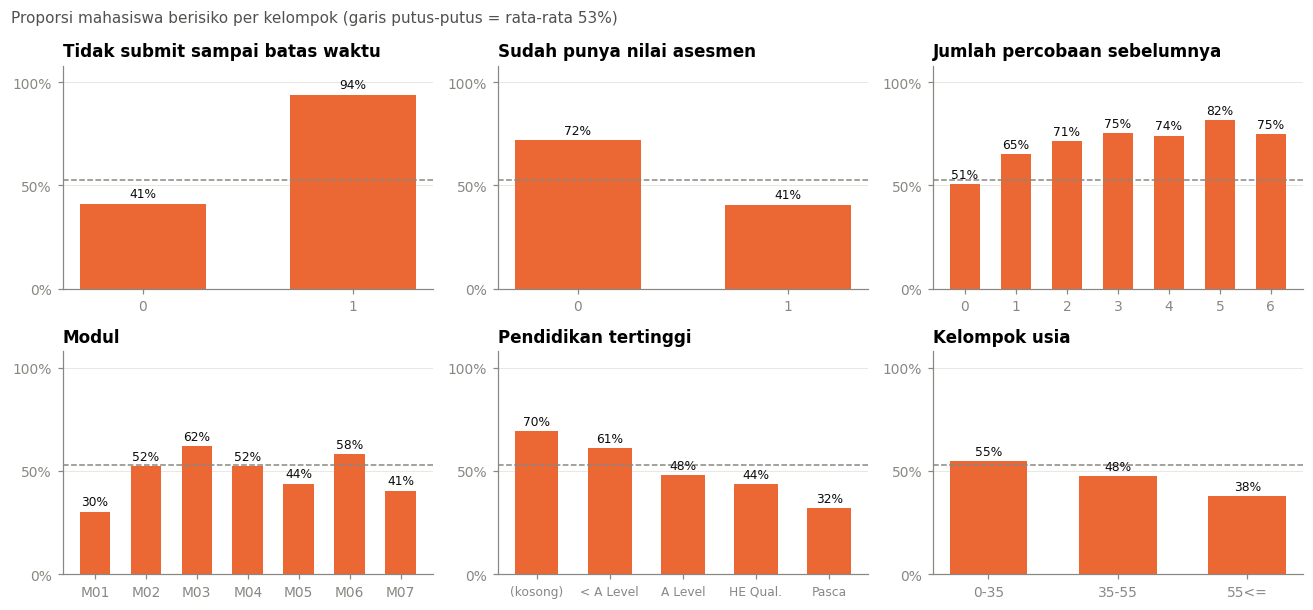

In [7]:
def rate_plot(ax, col, title, order=None):
    g = train.groupby(col)[TARGET].agg(["mean", "size"])
    if order is not None: g = g.reindex(order)
    b = ax.bar(g.index.astype(str), g["mean"], color=C1, width=0.6)
    ax.bar_label(b, labels=[f"{m:.0%}" for m in g["mean"]], padding=2, color=INK, fontsize=8)
    ax.axhline(train[TARGET].mean(), color=MUTED, lw=1, ls="--")
    ax.set_ylim(0, 1.08); ax.set_title(title); ax.grid(axis="x", visible=False)
    ax.set_yticks([0, .5, 1]); ax.set_yticklabels(["0%", "50%", "100%"])

fig, axes = plt.subplots(2, 3, figsize=(12, 5.6))
rate_plot(axes[0, 0], "no_submission_by_cutoff", "Tidak submit sampai batas waktu")
rate_plot(axes[0, 1], "has_score", "Sudah punya nilai asesmen")
rate_plot(axes[0, 2], "num_of_prev_attempts", "Jumlah percobaan sebelumnya")
rate_plot(axes[1, 0], "code_module", "Modul")
rate_plot(axes[1, 1], "highest_education", "Pendidikan tertinggi", order=["-", "Lower Than A Level", "A Level", "HE Qualification", "Post Graduate Qualification"])
axes[1, 1].set_xticklabels(["(kosong)", "< A Level", "A Level", "HE Qual.", "Pasca"], fontsize=8)
rate_plot(axes[1, 2], "age_band", "Kelompok usia")
fig.suptitle("Proporsi mahasiswa berisiko per kelompok (garis putus-putus = rata-rata 53%)", x=0.01, ha="left", fontsize=10, color="#52514e")
plt.tight_layout(); plt.show()

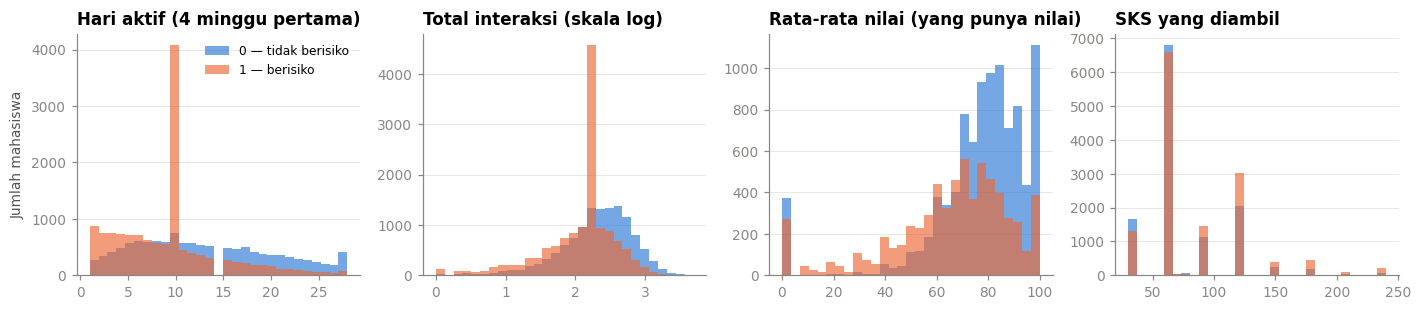

In [8]:
feats = ["active_days", "interaction_volume", "avg_score", "studied_credits"]
titles = ["Hari aktif (4 minggu pertama)", "Total interaksi (skala log)", "Rata-rata nilai (yang punya nilai)", "SKS yang diambil"]
fig, axes = plt.subplots(1, 4, figsize=(13, 2.9))
for ax, c, t in zip(axes, feats, titles):
    d = train[train.has_score == 1] if c == "avg_score" else train
    v = np.log10(d[c]) if c == "interaction_volume" else d[c].clip(upper=d[c].quantile(.99))
    bins = np.linspace(v.min(), v.max(), 30)
    ax.hist(v[d[TARGET] == 0], bins=bins, color=C0, alpha=.65, label="0 — tidak berisiko")
    ax.hist(v[d[TARGET] == 1], bins=bins, color=C1, alpha=.65, label="1 — berisiko")
    ax.set_title(t); ax.grid(axis="x", visible=False)
axes[0].legend(frameon=False, fontsize=8); axes[0].set_ylabel("Jumlah mahasiswa")
plt.tight_layout(); plt.show()

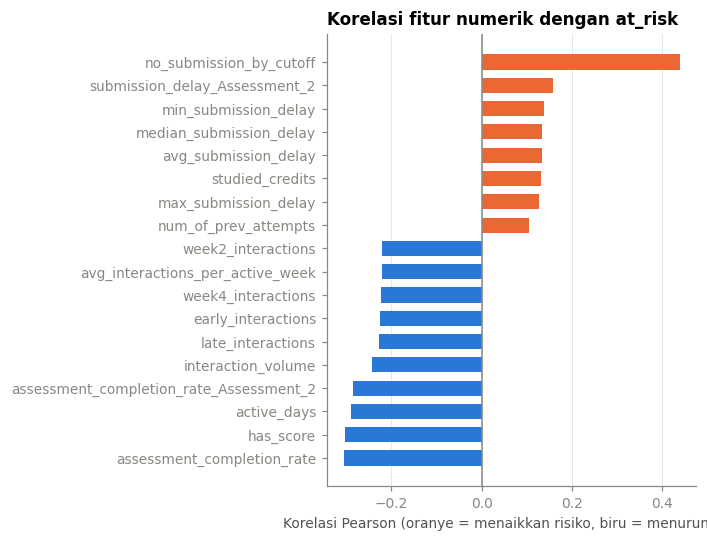

In [9]:
corr = train[[c for c in num_cols if c not in const_cols] + [TARGET]].corr()[TARGET].drop(TARGET).sort_values()
top = pd.concat([corr.head(10), corr.tail(8)])
fig, ax = plt.subplots(figsize=(6.5, 5))
ax.barh(top.index, top.values, color=[C0 if v < 0 else C1 for v in top.values], height=0.65)
ax.axvline(0, color=MUTED, lw=1); ax.grid(axis="y", visible=False)
ax.set_title("Korelasi fitur numerik dengan at_risk"); ax.set_xlabel("Korelasi Pearson (oranye = menaikkan risiko, biru = menurunkan)")
plt.tight_layout(); plt.show()

Ringkasan EDA:

- Sinyal terkuat adalah **perilaku pada 4 minggu pertama**: tidak mengumpulkan asesmen sampai batas waktu (94% berisiko), sedikit hari aktif, dan sedikit interaksi.
- Riwayat akademik ikut berpengaruh: makin banyak percobaan sebelumnya dan makin banyak SKS, makin tinggi risikonya.
- Risiko berbeda antarmodul (30%–62%), jadi `code_module` perlu dipertahankan.
- Banyak kolom nilai/keterlambatan saling redundan (`avg = median = max = min` ketika hanya ada satu asesmen) — tidak masalah untuk model pohon.

## 3. Preprocessing

### 3.1 Pembersihan

Langkah yang dilakukan, semuanya berasal dari temuan EDA:

1. `code_module`: `GGG` → `M07`.
2. `region`: hapus spasi dan samakan kapitalisasi.
3. `highest_education`: samakan kapitalisasi; `-` dijadikan kategori `Unknown`.
4. `imd_band`: `-` dan `?` dibiarkan sebagai kategori tersendiri.
5. Buang dua kolom konstan. `id` tidak dipakai sebagai fitur mentah (rentangnya berbeda antara train dan test), tetapi **urutannya** dipakai di bagian 3.2.
6. Label **tidak** diubah dan tidak ada baris yang dibuang.

Fitur turunan biasa (rasio interaksi, peringkat dalam modul-presentasi, penanda nilai imputasi) sudah dicoba dan tidak menaikkan skor validasi silang, karena kolom yang tersedia sudah berupa agregat dan model pohon sudah menangkapnya. Satu-satunya tambahan yang terbukti berguna adalah fitur tautan mahasiswa mengulang (3.2).

In [10]:
DROP_COLS = ["id", "submitted_Assessment_1", "submitted_Assessment_2"]

def clean(df):
    df = df.copy()
    df["code_module"] = df["code_module"].replace({"GGG": "M07"})
    df["region"] = df["region"].str.replace(" ", "", regex=False).str.capitalize()
    df["highest_education"] = df["highest_education"].str.title().replace({"-": "Unknown"})
    return df

y = train[TARGET].values
n_train = len(train)
full_id = clean(pd.concat([train.drop(columns=TARGET), test], ignore_index=True))
print("Baris:", full_id.shape[0], "| kategori region:", full_id.region.nunique(), "| modul:", sorted(full_id.code_module.unique()))

Baris: 32588 | kategori region: 13 | modul: ['M01', 'M02', 'M03', 'M04', 'M05', 'M06', 'M07']


### 3.2 Fitur tautan: mahasiswa yang mengulang modul

**Gagasan.** Jika seorang mahasiswa muncul lagi di presentasi berikutnya pada modul yang sama dengan `num_of_prev_attempts` bertambah satu, berarti percobaan sebelumnya tidak lulus. Jadi baris "pendahulu" hampir pasti `at_risk = 1`. Dataset tidak punya ID mahasiswa, sehingga tautannya direkonstruksi dari dua hal:

1. **Profil yang sama** — `gender`, `disability`, `region`, `highest_education`, `imd_band`, `age_band` identik, modul sama, presentasi lebih akhir, percobaan +1.
2. **Urutan baris** — di dalam tiap segmen (deretan `id` berurutan pada blok modul-presentasi yang sama), baris tersusun menurut urutan yang sama untuk semua blok. Akibatnya pasangan yang benar-benar orang yang sama membentuk **kurva monoton** antara posisi relatif di blok awal dan blok akhir, sedangkan pasangan yang kebetulan berprofil sama tersebar acak.

**Cara kerja.** Untuk tiap pasangan blok: ambil kandidat yang hampir unik, cari rantai naik terpanjang (*longest increasing subsequence*) sebagai kurva, lalu ukur jarak (residual) tiap kandidat ke kurva itu. Untuk titik yang ikut membentuk kurva, residual dihitung tanpa titik itu sendiri (*leave-one-out*) supaya tidak bias ke nol.

**Catatan kejujuran.** Fitur ini hanya memakai kolom fitur dari `train.csv` dan `test.csv` — tidak memakai label, tidak memakai data eksternal. Namun ia memanfaatkan informasi dari presentasi *berikutnya*, sehingga dalam penerapan nyata (prediksi di minggu ke-4) fitur ini belum tersedia. Model tanpa fitur ini juga dievaluasi di bagian 5.5 sebagai pembanding.

In [11]:
import bisect

PROFILE = ["gender", "disability", "region", "highest_education", "imd_band", "age_band"]

def longest_increasing_chain(points):
    order = sorted(range(len(points)), key=lambda i: (points[i][0], points[i][1]))
    tails, tails_idx, prev = [], [], {}
    for i in order:
        k = bisect.bisect_right(tails, points[i][1])
        if k == len(tails): tails.append(points[i][1]); tails_idx.append(i)
        else: tails[k] = points[i][1]; tails_idx[k] = i
        prev[i] = tails_idx[k - 1] if k > 0 else None
    chain, i = [], tails_idx[-1]
    while i is not None: chain.append(i); i = prev[i]
    return chain[::-1]

def curve_residual(g, min_anchor=8, n_iter=3, tol=0.05):
    na = g.groupby("row")["row_s"].transform("size"); nb = g.groupby("row_s")["row"].transform("size")
    anchors = g[(na <= 2) & (nb <= 2)]
    if len(anchors) < min_anchor: return None
    A = anchors[["pos", "pos_s"]].values; P = A
    for _ in range(n_iter):
        L = np.array([P[i] for i in longest_increasing_chain([tuple(p) for p in P])])
        xs = np.r_[0, L[:, 0], 1]; ys = np.r_[0, L[:, 1], 1]
        P = A[np.abs(A[:, 1] - np.interp(A[:, 0], xs, ys)) < tol]
    x, v = g["pos"].values, g["pos_s"].values
    res = np.abs(v - np.interp(x, xs, ys))
    on_chain = {(a, b): i + 1 for i, (a, b) in enumerate(L)}
    for k in np.where(res < 1e-12)[0]:
        i = on_chain.get((x[k], v[k]))
        if i is not None:
            res[k] = abs(v[k] - np.interp(x[k], np.delete(xs, i), np.delete(ys, i)))
    return res

def id_runs(df):
    # segmen = deretan id berurutan dengan blok modul-presentasi yang sama
    blk = (df["code_module"] + "_" + df["code_presentation"]).values
    order = np.argsort(df["id"].values, kind="stable")
    b = blk[order]
    seg = np.empty(len(df), dtype=int)
    seg[order] = np.r_[0, np.cumsum(b[1:] != b[:-1])]
    return seg

def build_link_features(df, seg):
    d = df[["id", "code_module", "code_presentation", "num_of_prev_attempts"]].copy()
    d["row"] = np.arange(len(d))
    d["seg"] = seg
    d["block"] = d["code_module"] + "_" + d["code_presentation"]
    d["pidx"] = d["code_presentation"].map({"P11": 0, "P12": 1, "P21": 2, "P22": 3})
    grp = d.groupby(["seg", "block"])["id"]
    d["pos"] = (grp.rank() - 0.5) / grp.transform("size")          # posisi relatif dalam blok
    d["profile"] = df[PROFILE].astype(str).agg("|".join, axis=1)
    k = d[["row", "profile", "block", "code_module", "pidx", "num_of_prev_attempts", "pos"]]
    j = k.merge(k, on=["profile", "code_module"], suffixes=("", "_s"))
    cand = j[(j["pidx_s"] > j["pidx"]) & (j["num_of_prev_attempts_s"] == j["num_of_prev_attempts"] + 1)]
    scored = []
    for _, g in cand.groupby(["block", "block_s"]):
        r = curve_residual(g)
        if r is not None: scored.append(g.assign(res=r))
    scored = pd.concat(scored)
    F = pd.DataFrame(index=d["row"])
    F["retake_min_res"] = scored.groupby("row")["res"].min()                       # jarak ke kurva utk penerus terdekat
    F["retake_n_close"] = scored[scored["res"] < 0.02].groupby("row").size()        # jumlah penerus dekat kurva
    F["retake_n_cand"] = scored.groupby("row").size()                               # jumlah kandidat penerus
    F["prev_min_res"] = scored.groupby("row_s")["res"].min()                        # utk baris pengulang: jarak ke pendahulu
    F[["retake_n_close", "retake_n_cand"]] = F[["retake_n_close", "retake_n_cand"]].fillna(0)
    return F.reset_index(drop=True), scored

SEG = id_runs(full_id)
runs = pd.DataFrame({"seg": SEG, "blok": full_id.code_module + "_" + full_id.code_presentation, "id": full_id.id, "test": np.arange(len(full_id)) >= n_train})
r = runs.groupby("seg").agg(blok=("blok", "first"), id_awal=("id", "min"), id_akhir=("id", "max"), n=("id", "size"), test=("test", "first"))
print("Jumlah segmen — train:", int((~r.test).sum()), "| test:", int(r.test.sum()))
print("Blok M02_P11 di test muncul dua kali (dua potongan yang masing-masing terurut):")
display(r[r.test & (r.blok == "M02_P11")])

LINK_SHARP, link_pairs = build_link_features(full_id, SEG)
LINK_COLS = LINK_SHARP.columns.tolist()
print("Pasangan kandidat:", len(link_pairs), "| baris yang punya kandidat penerus:", int(LINK_SHARP.retake_min_res.notna().sum()))

chk = pd.DataFrame({"res": LINK_SHARP.retake_min_res[:n_train], "y": y}).dropna()
tab = chk.groupby(pd.cut(chk.res, [0, .005, .01, .02, .05, 1], include_lowest=True), observed=True)["y"].agg(["mean", "size"])
tab.columns = ["proporsi berisiko", "jumlah baris train"]
print("Rata-rata berisiko seluruh train:", round(y.mean(), 3))
tab.round(3)

Jumlah segmen — train: 26 | test: 44
Blok M02_P11 di test muncul dua kali (dua potongan yang masing-masing terurut):


,blok,id_awal,id_akhir,n,test
seg,,,,,
28,M02_P11,26170,26346,177,True
50,M02_P11,29416,29591,176,True


Pasangan kandidat: 9794 | baris yang punya kandidat penerus: 6585
Rata-rata berisiko seluruh train: 0.527


,proporsi berisiko,jumlah baris train
res,,
"(-0.001, 0.005]",0.891,851
"(0.005, 0.01]",0.715,235
"(0.01, 0.02]",0.621,311
"(0.02, 0.05]",0.559,753
"(0.05, 1.0]",0.512,3135


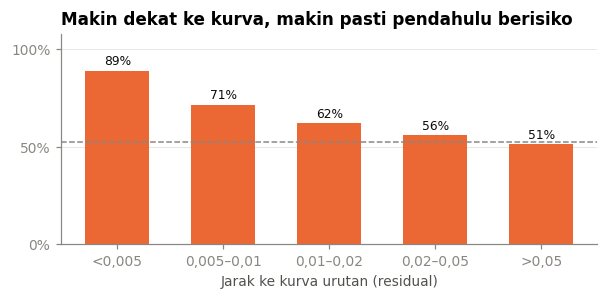

In [12]:
fig, ax = plt.subplots(figsize=(5.6, 2.8))
lab = ["<0,005", "0,005–0,01", "0,01–0,02", "0,02–0,05", ">0,05"]
b = ax.bar(lab, tab["proporsi berisiko"].values, color=C1, width=0.6)
ax.bar_label(b, labels=[f"{v:.0%}" for v in tab["proporsi berisiko"].values], padding=2, color=INK, fontsize=8)
ax.axhline(y.mean(), color=MUTED, lw=1, ls="--"); ax.set_ylim(0, 1.08); ax.grid(axis="x", visible=False)
ax.set_yticks([0, .5, 1]); ax.set_yticklabels(["0%", "50%", "100%"])
ax.set_xlabel("Jarak ke kurva urutan (residual)"); ax.set_title("Makin dekat ke kurva, makin pasti pendahulu berisiko")
plt.tight_layout(); plt.show()

Baris yang penerusnya jatuh tepat di kurva hampir semuanya berisiko, sedangkan kandidat yang jauh dari kurva (kebetulan berprofil sama) sama saja dengan rata-rata. Ini mengonfirmasi bahwa tautannya nyata, dan residual dapat dipakai model sebagai ukuran keyakinan.

**Menyamakan kondisi train dengan test.** Data test terdiri dari dua potongan (masing-masing ±10% data) yang terurut sendiri-sendiri, sehingga posisi relatif baris test lebih kasar daripada posisi baris train, dan residual tautannya lebih kabur. Jika model dilatih dengan residual train yang tajam lalu dipakai pada residual test yang kabur, model salah kalibrasi.

Solusinya: fitur tautan untuk baris train dihitung dalam kondisi yang sama dengan test. Train dibagi acak menjadi 8 potongan (±10% data per potongan); tiap potongan bergantian diperlakukan sebagai segmen terpisah, lalu fiturnya dihitung ulang. Dengan begitu skor validasi silang dan threshold mencerminkan kondisi test.

In [13]:
N_CHUNK = 8
chunk = np.random.RandomState(SEED).randint(0, N_CHUNK, size=n_train)
LINK = LINK_SHARP.copy()
for k in range(N_CHUNK):
    rows = np.where(chunk == k)[0]
    seg_k = SEG.copy(); seg_k[rows] = SEG.max() + 1
    LINK.iloc[rows] = build_link_features(full_id, seg_k)[0].iloc[rows].values

is_te = np.arange(len(LINK)) >= n_train
cmp = pd.DataFrame({
    "train, tajam": [(LINK_SHARP.retake_min_res[~is_te] < t).mean() for t in (.005, .02)],
    "train, disamakan": [(LINK.retake_min_res[~is_te] < t).mean() for t in (.005, .02)],
    "test": [(LINK.retake_min_res[is_te] < t).mean() for t in (.005, .02)],
}, index=["porsi baris residual < 0,005", "porsi baris residual < 0,02"])
cmp.round(4)

,"train, tajam","train, disamakan",test
"porsi baris residual < 0,005",0.0326,0.0170,0.0166
"porsi baris residual < 0,02",0.0536,0.0452,0.0444


Setelah disamakan, sebaran residual train mendekati sebaran test. Fitur inilah yang dipakai untuk melatih model.

In [14]:
full = pd.concat([full_id.drop(columns=DROP_COLS), LINK], axis=1)
CAT_COLS = full.select_dtypes("object").columns.tolist()
NUM_COLS = [c for c in full.columns if c not in CAT_COLS]

# Dua representasi kategori: dtype category (LightGBM) dan kode ordinal (XGBoost, CatBoost).
# Daftar kategori diambil dari gabungan train+test agar pengkodeannya konsisten.
X_cat = full.copy()
for c in CAT_COLS: X_cat[c] = X_cat[c].astype("category")
X_ord = full.copy()
for c in CAT_COLS: X_ord[c] = X_ord[c].astype("category").cat.codes

for c in CAT_COLS:
    assert set(full[c][n_train:]) <= set(full[c][:n_train]), c
print("Jumlah fitur:", full.shape[1], "| kategorikal:", len(CAT_COLS), "| numerik:", len(NUM_COLS))
print("Semua kategori di test sudah ada di train.")

Jumlah fitur: 64 | kategorikal: 8 | numerik: 56
Semua kategori di test sudah ada di train.


## 4. Pemilihan Model

**Skema validasi:** Stratified 5-fold, seed tetap. Setiap model menghasilkan prediksi *out-of-fold* (OOF) untuk seluruh data train, sehingga semua model dibandingkan pada data yang tidak dilihatnya saat latihan.

**Kandidat:**

| Model | Alasan |
|---|---|
| Logistic Regression | Baseline linear, pembanding sederhana |
| LightGBM | Gradient boosting, menangani kategori secara native |
| XGBoost | Gradient boosting dengan regularisasi berbeda |
| CatBoost | Pohon simetris, cenderung stabil |
| Blend | Rata-rata probabilitas tiga model boosting |

Model boosting memakai *early stopping* pada fold validasi. Prediksi test adalah rata-rata dari 5 model fold.

In [15]:
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
folds = list(skf.split(np.zeros(n_train), y))

def fit_logreg(Xa, ya, Xb, yb, Xt):
    num = make_pipeline(SimpleImputer(strategy="constant", fill_value=1.0), StandardScaler())   # residual kosong = tidak ada tautan
    pre = ColumnTransformer([("num", num, NUM_COLS), ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_COLS)])
    m = make_pipeline(pre, LogisticRegression(C=1.0, max_iter=2000, random_state=SEED)).fit(Xa, ya)
    return m.predict_proba(Xb)[:, 1], m.predict_proba(Xt)[:, 1], None

def fit_lgb(Xa, ya, Xb, yb, Xt):
    m = lgb.LGBMClassifier(n_estimators=3000, learning_rate=0.02, num_leaves=15, min_child_samples=60,
                           subsample=0.8, subsample_freq=1, colsample_bytree=0.4, reg_lambda=10,
                           random_state=SEED, n_jobs=N_JOBS, deterministic=True, force_row_wise=True, verbose=-1)
    m.fit(Xa, ya, eval_set=[(Xb, yb)], callbacks=[lgb.early_stopping(150, verbose=False)])
    return m.predict_proba(Xb)[:, 1], m.predict_proba(Xt)[:, 1], m

def fit_xgb(Xa, ya, Xb, yb, Xt):
    m = xgb.XGBClassifier(n_estimators=3000, learning_rate=0.02, max_depth=5, min_child_weight=5,
                          subsample=0.8, colsample_bytree=0.4, reg_lambda=5, tree_method="hist",
                          early_stopping_rounds=150, random_state=SEED, n_jobs=N_JOBS)
    m.fit(Xa, ya, eval_set=[(Xb, yb)], verbose=False)
    return m.predict_proba(Xb)[:, 1], m.predict_proba(Xt)[:, 1], m

def fit_cat(Xa, ya, Xb, yb, Xt):
    m = CatBoostClassifier(iterations=3000, learning_rate=0.05, depth=6, early_stopping_rounds=150,
                           random_seed=SEED, thread_count=N_JOBS, verbose=0)
    m.fit(Xa, ya, eval_set=(Xb, yb))
    return m.predict_proba(Xb)[:, 1], m.predict_proba(Xt)[:, 1], m

def run_cv(name, fit_fn, X):
    t0 = time.time()
    Xtr, Xte = X.iloc[:n_train], X.iloc[n_train:]
    oof, pred, models = np.zeros(n_train), np.zeros(len(Xte)), []
    for a, b in folds:
        p_val, p_test, m = fit_fn(Xtr.iloc[a], y[a], Xtr.iloc[b], y[b], Xte)
        oof[b] = p_val; pred += p_test / N_FOLDS; models.append(m)
    print(f"{name:20s} AUC OOF = {roc_auc_score(y, oof):.5f}   ({time.time() - t0:.0f} dtk)")
    return oof, pred, models

OOF, PRED, MODELS = {}, {}, {}
for name, fn, X in [("Logistic Regression", fit_logreg, full), ("LightGBM", fit_lgb, X_cat),
                    ("XGBoost", fit_xgb, X_ord), ("CatBoost", fit_cat, X_ord)]:
    OOF[name], PRED[name], MODELS[name] = run_cv(name, fn, X)

BLEND = ["LightGBM", "XGBoost", "CatBoost"]
OOF["Blend (LGB+XGB+CAT)"] = np.mean([OOF[m] for m in BLEND], axis=0)
PRED["Blend (LGB+XGB+CAT)"] = np.mean([PRED[m] for m in BLEND], axis=0)

Logistic Regression  AUC OOF = 0.84027   (3 dtk)


LightGBM             AUC OOF = 0.85005   (12 dtk)


XGBoost              AUC OOF = 0.84914   (18 dtk)


CatBoost             AUC OOF = 0.84843   (31 dtk)


In [16]:
THRESHOLDS = np.round(np.arange(0.20, 0.701, 0.01), 2)

def f1_curve(p):
    return np.array([f1_score(y, p > t) for t in THRESHOLDS])

rows = []
for name, p in OOF.items():
    fc = f1_curve(p)
    rows.append({"model": name, "AUC": roc_auc_score(y, p), "F1 @0.50": f1_score(y, p > 0.5),
                 "F1 terbaik": fc.max(), "threshold terbaik": THRESHOLDS[fc.argmax()]})
results = pd.DataFrame(rows).set_index("model").sort_values("F1 terbaik", ascending=False)
results.round(5)

,AUC,F1 @0.50,F1 terbaik,threshold terbaik
model,,,,
Blend (LGB+XGB+CAT),0.85039,0.76629,0.77787,0.36
LightGBM,0.85005,0.76777,0.77670,0.39
XGBoost,0.84914,0.76567,0.77660,0.36
CatBoost,0.84843,0.76278,0.77592,0.39
Logistic Regression,0.84027,0.75845,0.76969,0.42


Cara membaca tabel: `AUC` mengukur kualitas pengurutan probabilitas, `F1 @0.50` adalah F1 dengan threshold bawaan, dan `F1 terbaik` adalah F1 pada threshold optimal di data OOF.

**Model terpilih: blend LightGBM + XGBoost + CatBoost.** Ketiga model boosting mengungguli baseline linear, dan rata-rata ketiganya memberi AUC dan F1 OOF tertinggi sekaligus lebih stabil daripada satu model tunggal. Selisih antarmodel boosting kecil, yang menunjukkan skor sudah mendekati batas informasi yang tersedia di fitur.

## 5. Evaluasi Model

### 5.1 Optimasi threshold

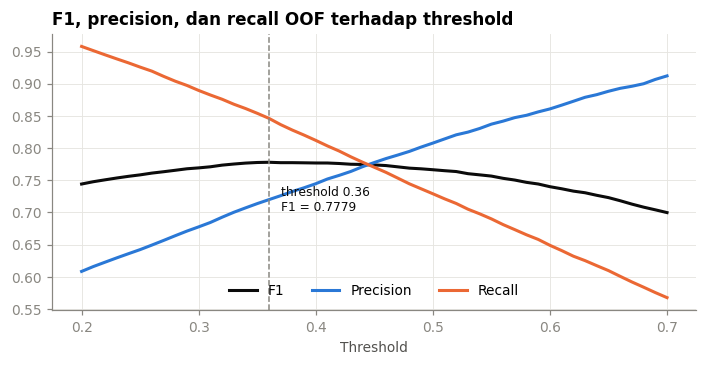

Threshold terpilih: 0.36
F1 OOF @ 0.36 = 0.77787   |   F1 OOF @ 0.50 = 0.76629
Rentang threshold dengan F1 dalam 0,001 dari maksimum: 0.35 - 0.39


In [17]:
FINAL = "Blend (LGB+XGB+CAT)"
oof_final, pred_final = OOF[FINAL], PRED[FINAL]

fc = f1_curve(oof_final)
BEST_T = float(THRESHOLDS[fc.argmax()])
prec = [precision_score(y, oof_final > t) for t in THRESHOLDS]
rec = [recall_score(y, oof_final > t) for t in THRESHOLDS]

fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.plot(THRESHOLDS, fc, color=INK, lw=2, label="F1")
ax.plot(THRESHOLDS, prec, color=C0, lw=2, label="Precision")
ax.plot(THRESHOLDS, rec, color=C1, lw=2, label="Recall")
ax.axvline(BEST_T, color=MUTED, lw=1, ls="--")
ax.annotate(f"threshold {BEST_T:.2f}\nF1 = {fc.max():.4f}", (BEST_T, fc.max()), xytext=(8, -32), textcoords="offset points", color=INK, fontsize=8)
ax.set_xlabel("Threshold"); ax.set_title("F1, precision, dan recall OOF terhadap threshold"); ax.legend(frameon=False, ncol=3, loc="lower center")
plt.tight_layout(); plt.show()

print(f"Threshold terpilih: {BEST_T:.2f}")
print(f"F1 OOF @ {BEST_T:.2f} = {fc.max():.5f}   |   F1 OOF @ 0.50 = {f1_score(y, oof_final > 0.5):.5f}")
near = THRESHOLDS[fc >= fc.max() - 0.001]
print(f"Rentang threshold dengan F1 dalam 0,001 dari maksimum: {near.min():.2f} - {near.max():.2f}")

F1 kelas positif maksimal pada threshold di bawah 0,5: menurunkan threshold menaikkan recall lebih banyak daripada turunnya precision. Kurva F1 landai di sekitar puncaknya, sehingga pilihan threshold tidak sensitif terhadap pergeseran kecil.

### 5.2 Kestabilan antar-fold dan matriks kebingungan

In [18]:
fold_f1 = [f1_score(y[b], oof_final[b] > BEST_T) for _, b in folds]
fold_auc = [roc_auc_score(y[b], oof_final[b]) for _, b in folds]
print("F1 per fold :", np.round(fold_f1, 4), f"-> rata-rata {np.mean(fold_f1):.4f} ± {np.std(fold_f1):.4f}")
print("AUC per fold:", np.round(fold_auc, 4), f"-> rata-rata {np.mean(fold_auc):.4f} ± {np.std(fold_auc):.4f}")

oof_label = (oof_final > BEST_T).astype(int)
cm = confusion_matrix(y, oof_label)
print("\nMatriks kebingungan (baris = aktual, kolom = prediksi):")
display(pd.DataFrame(cm, index=["aktual 0", "aktual 1"], columns=["prediksi 0", "prediksi 1"]))
print(classification_report(y, oof_label, digits=4, target_names=["0 — tidak berisiko", "1 — berisiko"]))

F1 per fold : [0.7737 0.7845 0.7836 0.7687 0.7788] -> rata-rata 0.7779 ± 0.0060
AUC per fold: [0.8478 0.8582 0.8525 0.842  0.8517] -> rata-rata 0.8505 ± 0.0053

Matriks kebingungan (baris = aktual, kolom = prediksi):


,prediksi 0,prediksi 1
aktual 0,7803,4530
aktual 1,2116,11637


                    precision    recall  f1-score   support

0 — tidak berisiko     0.7867    0.6327    0.7013     12333
      1 — berisiko     0.7198    0.8461    0.7779     13753

          accuracy                         0.7452     26086
         macro avg     0.7532    0.7394    0.7396     26086
      weighted avg     0.7514    0.7452    0.7417     26086



### 5.3 Performa per modul

In [19]:
mod = full["code_module"].iloc[:n_train].values
rows = []
for m in sorted(set(mod)):
    k = mod == m
    rows.append({"modul": m, "n": int(k.sum()), "proporsi berisiko": y[k].mean(), "F1": f1_score(y[k], oof_label[k]), "AUC": roc_auc_score(y[k], oof_final[k])})
per_mod = pd.DataFrame(rows).set_index("modul")
per_mod.round(4)

,n,proporsi berisiko,F1,AUC
modul,,,,
M01,602,0.3040,0.6064,0.8030
M02,6368,0.5231,0.7701,0.8464
M03,3568,0.6200,0.8361,0.8763
M04,6303,0.5239,0.7787,0.8496
M05,2343,0.4392,0.7158,0.8318
M06,5066,0.5825,0.8211,0.8712
M07,1836,0.4058,0.6017,0.6967


Modul `M07` penting diperhatikan karena baris `GGG` di data test dipetakan ke modul ini.

### 5.4 Fitur terpenting

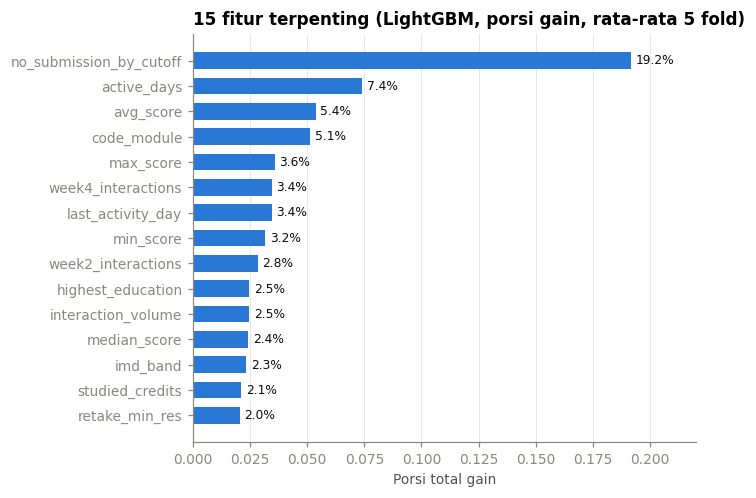

In [20]:
imp = pd.DataFrame({i: pd.Series(m.booster_.feature_importance("gain"), index=X_cat.columns) for i, m in enumerate(MODELS["LightGBM"])})
imp = (imp / imp.sum()).mean(axis=1).sort_values().tail(15)

fig, ax = plt.subplots(figsize=(6.5, 4.6))
b = ax.barh(imp.index, imp.values, color=C0, height=0.65)
ax.bar_label(b, labels=[f"{v:.1%}" for v in imp.values], padding=3, color=INK, fontsize=8)
ax.set_xlim(0, imp.max() * 1.15); ax.grid(axis="y", visible=False)
ax.set_title("15 fitur terpenting (LightGBM, porsi gain, rata-rata 5 fold)"); ax.set_xlabel("Porsi total gain")
plt.tight_layout(); plt.show()

### 5.5 Kontribusi fitur tautan (ablasi)

In [21]:
X_no = X_cat.drop(columns=LINK_COLS)
oof_no, _, _ = run_cv("LightGBM tanpa tautan", fit_lgb, X_no)
abl = pd.DataFrame({
    "AUC": [roc_auc_score(y, oof_no), roc_auc_score(y, OOF["LightGBM"])],
    "F1 terbaik": [f1_curve(oof_no).max(), f1_curve(OOF["LightGBM"]).max()],
}, index=["LightGBM tanpa fitur tautan", "LightGBM dengan fitur tautan"])

strong = (LINK_SHARP.retake_min_res[:n_train] < 0.005).values
print(f"Baris train dengan tautan kuat: {strong.sum()} | aktual berisiko {y[strong].mean():.1%}")
print(f"  diprediksi tidak berisiko — tanpa tautan: {(oof_no[strong] <= BEST_T).mean():.1%} | dengan tautan: {(OOF['LightGBM'][strong] <= BEST_T).mean():.1%}")
abl.round(5)

LightGBM tanpa tautan AUC OOF = 0.84640   (12 dtk)


Baris train dengan tautan kuat: 851 | aktual berisiko 89.1%
  diprediksi tidak berisiko — tanpa tautan: 21.6% | dengan tautan: 6.9%


,AUC,F1 terbaik
LightGBM tanpa fitur tautan,0.84640,0.77395
LightGBM dengan fitur tautan,0.85005,0.77670


Kenaikan datang dari sekelompok kecil mahasiswa yang sebelumnya diprediksi aman padahal kemudian mengulang modul. Di luar kelompok itu perilaku model tidak berubah.

## 6. Prediksi Data Test & File Submission

Probabilitas test adalah rata-rata 5 model fold dari tiap algoritma, lalu dirata-ratakan antar-algoritma dan dipotong dengan threshold hasil OOF.

In [22]:
submission = pd.DataFrame({"id": test["id"].values, TARGET: (pred_final > BEST_T).astype(int)})

assert list(submission.columns) == list(sample_sub.columns)
assert len(submission) == len(sample_sub) and (submission["id"].values == sample_sub["id"].values).all()
assert submission["id"].is_unique and set(submission[TARGET]) <= {0, 1}

out_path = f"{OUT_DIR}submission_{SUBMISSION_NO}.csv"
submission.to_csv(out_path, index=False)

print("Tersimpan:", out_path, "|", submission.shape)
print(f"Proporsi prediksi berisiko — test: {submission[TARGET].mean():.4f} | OOF train: {oof_label.mean():.4f} | label train: {y.mean():.4f}")
print(f"Rata-rata probabilitas — test: {pred_final.mean():.4f} | OOF train: {oof_final.mean():.4f}")
submission.head()

Tersimpan: ../submissions/submission_3.csv | (6502, 2)
Proporsi prediksi berisiko — test: 0.6150 | OOF train: 0.6198 | label train: 0.5272
Rata-rata probabilitas — test: 0.5272 | OOF train: 0.5274


,id,at_risk
0,26092,0
1,26093,0
2,26094,0
3,26095,0
4,26096,0


## 7. Insight Preskriptif

Berdasarkan EDA dan fitur terpenting model:

1. **Asesmen pertama adalah sinyal paling tegas.** Mahasiswa yang tidak mengumpulkan asesmen sampai batas waktu hampir pasti berisiko (≈94%). Rekomendasi: pengingat otomatis sebelum tenggat dan kontak langsung dari tutor dalam 48 jam setelah tenggat terlewat.
2. **Keterlibatan 4 minggu pertama menentukan.** Hari aktif dan volume interaksi yang rendah berkaitan erat dengan risiko. Rekomendasi: pantau keaktifan mingguan dan hubungi mahasiswa yang tidak aktif sejak minggu ke-2, jangan menunggu asesmen.
3. **Beban studi dan riwayat mengulang.** Risiko naik seiring jumlah SKS dan jumlah percobaan sebelumnya. Rekomendasi: konseling beban studi saat registrasi dan pendampingan khusus bagi mahasiswa yang mengulang.
4. **Risiko berbeda antarmodul.** Modul dengan proporsi berisiko tinggi layak ditinjau desain awal dan beban asesmennya.
5. **Mengulang modul adalah pola yang terlihat di data.** Sebagian mahasiswa berisiko kembali mendaftar di presentasi berikutnya. Rekomendasi: saat pendaftaran ulang, tawarkan jalur pendampingan sejak minggu pertama, karena kelompok ini sudah terbukti pernah gagal di modul yang sama.

**Batasan fitur tautan.** Fitur tautan memakai data presentasi berikutnya, jadi berguna untuk analisis retrospektif dan untuk kompetisi ini, tetapi untuk sistem peringatan dini yang berjalan di minggu ke-4 yang dipakai adalah model tanpa fitur tersebut (lihat 5.5).

**Pemakaian skor model:** probabilitas dapat dipakai untuk memprioritaskan intervensi — kelompok probabilitas tertinggi dihubungi tutor secara personal, kelompok menengah diberi pengingat otomatis. Threshold yang rendah sengaja mengutamakan recall: lebih baik menghubungi mahasiswa yang ternyata aman daripada melewatkan yang benar-benar berisiko.